# program 1

In [1]:
import pandas as pd
import numpy as np


data = pd.DataFrame([
    ['sunny', 'warm', 'normal', 'strong', 'warm', 'same', 'yes'],
    ['sunny', 'warm', 'high', 'strong', 'warm', 'same', 'yes'],
    ['rainy', 'cold', 'high', 'strong', 'warm', 'change', 'no'],
    ['sunny', 'warm', 'high', 'strong', 'cool', 'change', 'yes']
], columns=['Sky', 'AirTemp', 'Humidity', 'Wind', 'Water', 'Forecast', 'EnjoySport'])

print("Initial Dataset:")
print(data)
print("-" * 50)


def find_s(data):

    print("--- Running Find-S Algorithm ---")


    positive_examples = data[data['EnjoySport'] == 'yes'].iloc[:, :-1].values


    hypothesis = positive_examples[0].copy().tolist()

    print(f"Initial hypothesis (from first positive example): {hypothesis}")


    for i, example in enumerate(positive_examples[1:]):
        print(f"Processing positive example {i+2}: {example}")

        for j in range(len(hypothesis)):

            if example[j] != hypothesis[j]:
                hypothesis[j] = '?'
        print(f"Hypothesis after processing: {hypothesis}")

    return hypothesis


final_hypothesis_find_s = find_s(data)

print("\nFinal hypothesis from Find-S algorithm:", final_hypothesis_find_s)
print("-" * 50)


def candidate_elimination(data):

    print("--- Running Candidate Elimination Algorithm ---")


    attributes = data.columns[:-1].tolist()


    initial_positive_example = data[data['EnjoySport'] == "yes"].iloc[0, :-1].values
    S = [initial_positive_example.tolist()]

    G = [['?' for _ in attributes]]


    for i, (_, example) in enumerate(data.iterrows()):
        print(f"\nProcessing example {i+1}: {example.tolist()}")

        example_features = example.iloc[:-1].tolist()
        example_class = example.iloc[-1]

        if example_class == 'yes':

            G = [g for g in G if is_consistent(g, example_features)]

            new_S = []
            for s in S:
                if not is_consistent(s, example_features):

                    new_hypotheses = generalize_s(s, example_features, attributes)

                    new_S.extend(new_hypotheses)
                else:
                    new_S.append(s)

            S = new_S

            S = prune(S, G)

        elif example_class == 'no':

            S = [s for s in S if not is_consistent(s, example_features)]

            new_G = []
            for g in G:
                if is_consistent(g, example_features):

                    new_hypotheses = specialize_g(g, example_features, attributes)

                    new_G.extend(new_hypotheses)
                else:
                    new_G.append(g)

            G = new_G


        print(f"Current S boundary: {S}")
        print(f"Current G boundary: {G}")

    return S, G



def is_consistent(hypothesis, example):

    for h_val, e_val in zip(hypothesis, example):
        if h_val != '?' and h_val != e_val:
            return False
    return True


def generalize_s(s, example, attributes):

    new_hypotheses = []
    for i in range(len(s)):
        if s[i] != example[i]:
            new_s = s.copy()
            new_s[i] = '?'
            new_hypotheses.append(new_s)
    return new_hypotheses


def specialize_g(g, example, attributes):

    new_hypotheses = []
    for i in range(len(g)):
        if g[i] == '?':
            for value in set(example):
                new_g = g.copy()
                new_g[i] = value
                new_hypotheses.append(new_g)
    return new_hypotheses


def prune(S, G):

    unique_S = []
    for s_hyp in S:
        if s_hyp not in unique_S:
            unique_S.append(s_hyp)
    return unique_S


def prune_g(G, S):

    unique_G = []
    for g_hyp in G:
        if g_hyp not in unique_G:
            unique_G.append(g_hyp)
    return unique_G



final_S, final_G = candidate_elimination(data)

print("\n--- Final Results for Candidate Elimination ---")
print("Final Version Space:")
print("Specific boundary (S):", final_S)
print("General boundary (G):", final_G)

print("\nMost specific hypothesis in the version space:", final_S[0])
print("Most general hypothesis in the version space:", final_G[0])

Initial Dataset:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  sunny    warm   normal  strong  warm     same        yes
1  sunny    warm     high  strong  warm     same        yes
2  rainy    cold     high  strong  warm   change         no
3  sunny    warm     high  strong  cool   change        yes
--------------------------------------------------
--- Running Find-S Algorithm ---
Initial hypothesis (from first positive example): ['sunny', 'warm', 'normal', 'strong', 'warm', 'same']
Processing positive example 2: ['sunny' 'warm' 'high' 'strong' 'warm' 'same']
Hypothesis after processing: ['sunny', 'warm', '?', 'strong', 'warm', 'same']
Processing positive example 3: ['sunny' 'warm' 'high' 'strong' 'cool' 'change']
Hypothesis after processing: ['sunny', 'warm', '?', 'strong', '?', '?']

Final hypothesis from Find-S algorithm: ['sunny', 'warm', '?', 'strong', '?', '?']
--------------------------------------------------
--- Running Candidate Elimination Algorithm ---

Pro

# program 2

In [2]:


import pandas as pd
import math



def train_ripper_or_cn2_like(data):

    print("--- 1. Generating propositional rules with a RIPPER/CN2-like method ---")
    print("The algorithm iteratively finds the best rules and adds them to a rule set.")
    print("\nSimulated Rules Generated:")

    print("RULE 1: IF age <= 30 AND education = 'High School' THEN class = 'Low'")


    print("RULE 2: IF marital_status = 'Married' AND occupation = 'Manager' THEN class = 'High'")


    print("DEFAULT RULE: ELSE class = 'Medium'")
    print("\nRules are generated greedily, focusing on accuracy and coverage.")


def train_foil_like(examples):

    print("\n--- 2. Applying the FOIL algorithm for first-order rules ---")
    print("FOIL works by iteratively adding conditions (literals) to a rule")
    print("that provide the highest 'gain' until the rule is accurate.")


    print("Objective: Learn the rule for 'Grandparent(X,Z)'.")


    def calculate_foil_gain(p0, n0, p1, n1):

        if p1 == 0:
            return 0
        gain_numerator = math.log2(p1 / (p1 + n1)) - math.log2(p0 / (p0 + n0))
        return p1 * gain_numerator


    p0 = 10
    n0 = 50

    print(f"Initial State: Rule is 'Grandparent(X,Z) :-' with {p0} positive and {n0} negative examples.")


    p1 = 8
    n1 = 15
    gain_parent_xy = calculate_foil_gain(p0, n0, p1, n1)
    print(f"Testing literal 'Parent(X,Y)' -> New state: {p1} pos, {n1} neg. Gain: {gain_parent_xy:.2f}")

    p0 = 8
    n0 = 15
    p1 = 8
    n1 = 0

    gain_parent_yz = calculate_foil_gain(p0, n0, p1, n1)
    print(f"Testing literal 'Parent(Y,Z)' -> New state: {p1} pos, {n1} neg. Gain: {gain_parent_yz:.2f}")


    print("\nConclusion: The algorithm adds the literals step-by-step, resulting in the rule:")
    print("Grandparent(X,Z) :- Parent(X,Y), Parent(Y,Z)")

def main():



    data = pd.DataFrame({
        'age': [25, 35, 50, 62, 30, 45, 22],
        'education': ['High School', 'College', 'College', 'PhD', 'High School', 'PhD', 'High School'],
        'marital_status': ['Single', 'Married', 'Married', 'Married', 'Single', 'Married', 'Single'],
        'occupation': ['Engineer', 'Manager', 'Analyst', 'Manager', 'Clerk', 'Manager', 'Clerk'],
        'class': ['Low', 'High', 'High', 'High', 'Low', 'High', 'Low']
    })

    train_ripper_or_cn2_like(data)


    train_foil_like(None)

if __name__ == "__main__":
    main()

--- 1. Generating propositional rules with a RIPPER/CN2-like method ---
The algorithm iteratively finds the best rules and adds them to a rule set.

Simulated Rules Generated:
RULE 1: IF age <= 30 AND education = 'High School' THEN class = 'Low'
RULE 2: IF marital_status = 'Married' AND occupation = 'Manager' THEN class = 'High'
DEFAULT RULE: ELSE class = 'Medium'

Rules are generated greedily, focusing on accuracy and coverage.

--- 2. Applying the FOIL algorithm for first-order rules ---
FOIL works by iteratively adding conditions (literals) to a rule
that provide the highest 'gain' until the rule is accurate.
Objective: Learn the rule for 'Grandparent(X,Z)'.
Initial State: Rule is 'Grandparent(X,Z) :-' with 10 positive and 50 negative examples.
Testing literal 'Parent(X,Y)' -> New state: 8 pos, 15 neg. Gain: 8.49
Testing literal 'Parent(Y,Z)' -> New state: 8 pos, 0 neg. Gain: 12.19

Conclusion: The algorithm adds the literals step-by-step, resulting in the rule:
Grandparent(X,Z) :- 

# program 3

In [3]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')


data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

base_estimator = DecisionTreeClassifier(random_state=42)


bagging_model = BaggingClassifier(
    estimator=base_estimator,
    n_estimators=50,
    random_state=42,
    bootstrap=True
)

bagging_model.fit(X_train, y_train)
y_pred_bag = bagging_model.predict(X_test)


boosting_model = AdaBoostClassifier(
    estimator=base_estimator,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

boosting_model.fit(X_train, y_train)
y_pred_boost = boosting_model.predict(X_test)


print("=== Bagging Performance ===")
print("Accuracy:", accuracy_score(y_test, y_pred_bag))
print(classification_report(y_test, y_pred_bag))

print("=== Boosting Performance ===")
print("Accuracy:", accuracy_score(y_test, y_pred_boost))
print(classification_report(y_test, y_pred_boost))

=== Bagging Performance ===
Accuracy: 0.956140350877193
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        43
           1       0.96      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

=== Boosting Performance ===
Accuracy: 0.9385964912280702
              precision    recall  f1-score   support

           0       0.93      0.91      0.92        43
           1       0.94      0.96      0.95        71

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



# program 4

Unsupervised dataset generated with 300 samples.
--------------------------------------------------
Training K-Means Clustering model...
K-Means Clustering complete. Found the following cluster centers:
[[ 0.94973532  4.41906906]
 [ 1.98258281  0.86771314]
 [-1.37324398  7.75368871]
 [-1.58438467  2.83081263]]
--------------------------------------------------


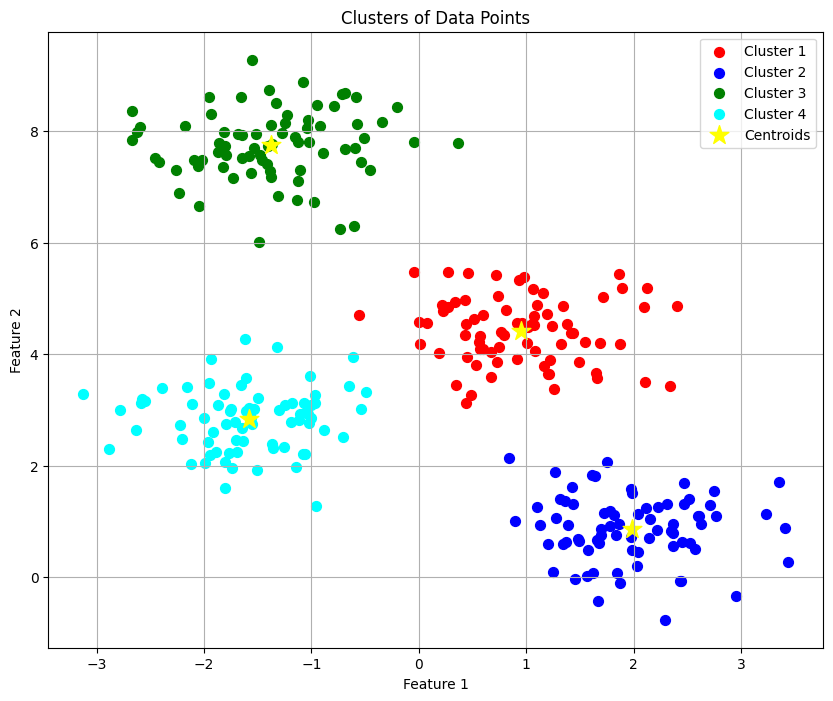

Visualization of the clusters is complete.


In [4]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
import warnings

warnings.filterwarnings('ignore')

X, y = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

print("Unsupervised dataset generated with 300 samples.")
print("-" * 50)

kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=0)

print("Training K-Means Clustering model...")

y_kmeans = kmeans.fit_predict(X)

cluster_centers = kmeans.cluster_centers_

print("K-Means Clustering complete. Found the following cluster centers:")
print(cluster_centers)
print("-" * 50)

plt.figure(figsize=(10, 8))

plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=50, c='red', label='Cluster 1')
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=50, c='blue', label='Cluster 2')
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=50, c='green', label='Cluster 3')
plt.scatter(X[y_kmeans == 3, 0], X[y_kmeans == 3, 1], s=50, c='cyan', label='Cluster 4')

plt.scatter(
    cluster_centers[:, 0],
    cluster_centers[:, 1],
    s=200,
    c='yellow',
    marker='*',
    label='Centroids'
)

plt.title('Clusters of Data Points')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

print("Visualization of the clusters is complete.")

In [6]:
!pip install MiniSom

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for MiniSom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=4a79cc4edddf4f283415e963fce9a2e57b16fd7abbb11dc842bf37fd166777e1
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built MiniSom


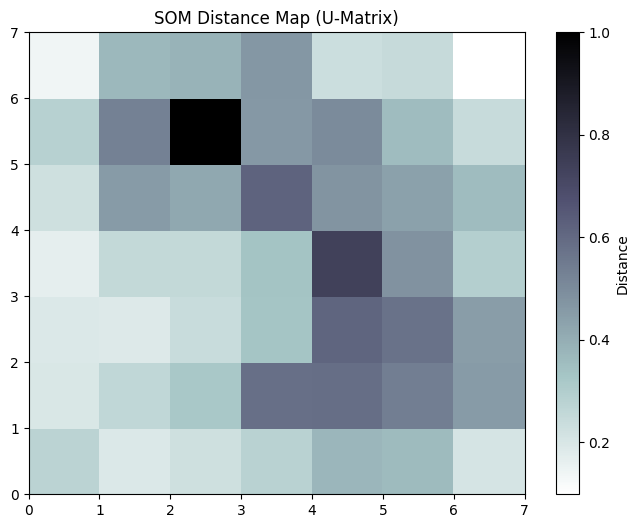

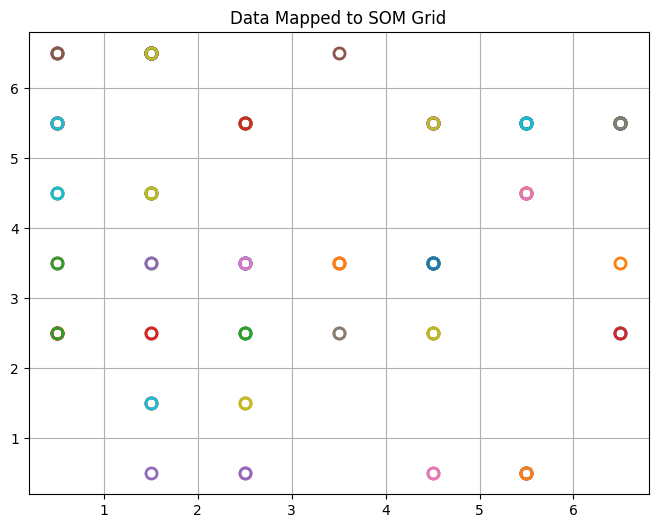

In [7]:
from minisom import MiniSom
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import numpy as np

data = load_iris()
X = data.data

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

som_grid_rows, som_grid_cols = 7, 7

som = MiniSom(
    som_grid_rows,
    som_grid_cols,
    X_scaled.shape[1],
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

som.random_weights_init(X_scaled)
som.train_random(X_scaled, num_iteration=100)

u_matrix = som.distance_map()

plt.figure(figsize=(8, 6))
plt.pcolor(u_matrix.T, cmap='bone_r')
plt.colorbar(label='Distance')
plt.title('SOM Distance Map (U-Matrix)')
plt.show()

plt.figure(figsize=(8, 6))

for i, x in enumerate(X_scaled):
    w = som.winner(x)
    plt.plot(
        w[0] + 0.5,
        w[1] + 0.5,
        'o',
        markerfacecolor='none',
        markeredgecolor='C{}'.format(i % 10),
        markersize=8,
        markeredgewidth=2
    )

plt.title('Data Mapped to SOM Grid')
plt.grid(True)
plt.show()

In [8]:
import math
import random

def uniform_random():
    return random.random()

samples = [uniform_random() for _ in range(10)]

def f(x):
    return math.exp(-x**2)

function_values = [f(x) for x in samples]

print("Random samples (x):", samples)
print("Function values f(x):", function_values)

I_estimate = sum(function_values) / len(function_values)
print(f"\nEstimated integral I ≈ {I_estimate:.5f}")

Random samples (x): [0.5676869655951753, 0.735434849675985, 0.2885542363065061, 0.671996778018777, 0.969655654600285, 0.881047802658012, 0.43636247668921835, 0.5225086797882059, 0.5527152685245587, 0.5105674545906164]
Function values f(x): [0.7245036415741826, 0.582244731883911, 0.9201086231287171, 0.6366217049073977, 0.39053718565059997, 0.4601304556030747, 0.8266183224881924, 0.761081127431201, 0.7367592015522988, 0.7705281226342974]

Estimated integral I ≈ 0.68091


In [9]:
!pip install pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 63.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


In [12]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

data = pd.DataFrame({
'Cold': ['Yes', 'Yes', 'Yes', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No'],
'Fever': ['Yes', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'Yes', 'Yes'],
'SoreThroat': ['Yes', 'Yes', 'No', 'No', 'No', 'No', 'No', 'Yes', 'Yes', 'Yes']
})

for col in data.columns:
    data[col] = data[col].astype('category')
print("Sample Dataset:")
print(data)
print("-" * 30)
#
model = DiscreteBayesianNetwork([
('Cold', 'Fever'),
('Cold', 'SoreThroat')
])

# By default, fit() uses Maximum Likelihood Estimation internally.
model.fit(data)

print("\nLearned Conditional Probability Distributions (CPDs):")
for cpd in model.get_cpds():
 print(f"\nCPD of {cpd.variable}:")
 print(cpd)
print("-" * 30)

inference = VariableElimination(model)
prob_fever = inference.query(variables=['Fever'], joint=False)
print("\nQuery 1: P(Fever)")
print(prob_fever['Fever'])

prob_fever_given_cold = inference.query(variables=['Fever'], evidence={'Cold': 'Yes'},
joint=False)
print("\nQuery 2: P(Fever | Cold = Yes)")
print(prob_fever_given_cold['Fever'])

# has a Sore Throat but no Fever?
# This shows how we can reason backward from symptoms to a cause.
prob_cold_given_symptoms = inference.query(
variables=['Cold'], evidence={'SoreThroat': 'Yes', 'Fever': 'No'}, joint=False
)
print("\nQuery 3: P(Cold | SoreThroat = Yes,Fever=no)")
# Fix: corrected lowercase 'cold' to capital 'Cold' to match the variable name
print(prob_cold_given_symptoms['Cold'])

Sample Dataset:
  Cold Fever SoreThroat
0  Yes   Yes        Yes
1  Yes    No        Yes
2  Yes   Yes         No
3  Yes    No         No
4   No    No         No
5   No    No         No
6   No    No         No
7   No    No        Yes
8   No   Yes        Yes
9   No   Yes        Yes
------------------------------

Learned Conditional Probability Distributions (CPDs):

CPD of Cold:
+-----------+-----+
| Cold(No)  | 0.6 |
+-----------+-----+
| Cold(Yes) | 0.4 |
+-----------+-----+

CPD of Fever:
+------------+--------------------+-----------+
| Cold       | Cold(No)           | Cold(Yes) |
+------------+--------------------+-----------+
| Fever(No)  | 0.6666666666666666 | 0.5       |
+------------+--------------------+-----------+
| Fever(Yes) | 0.3333333333333333 | 0.5       |
+------------+--------------------+-----------+

CPD of SoreThroat:
+-----------------+----------+-----------+
| Cold            | Cold(No) | Cold(Yes) |
+-----------------+----------+-----------+
| SoreThroat(No)  | 

In [13]:
!pip install -U pgmpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 125.2 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [15]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

data = pd.DataFrame({
    'Weather': ['Sunny','Sunny','Rainy','Rainy','Cloudy','Cloudy',
                'Sunny','Rainy','Cloudy','Sunny','Rainy','Cloudy'],
    'Humidity': ['High','Normal','High','Normal','High','Normal',
                 'High','High','Normal','Normal','High','Normal'],
    'Windy': ['No','Yes','No','Yes','No','Yes',
              'No','Yes','No','Yes','No','Yes'],
    'Play': ['No','Yes','No','Yes','Yes','Yes',
             'No','No','Yes','Yes','No','Yes']
})

print("DATASET")
print(data)

model = DiscreteBayesianNetwork([
    ('Weather', 'Play'),
    ('Humidity', 'Play'),
    ('Windy', 'Play')
])


model.fit(data)

inference = VariableElimination(model)

result1 = inference.query(
    variables=['Play'],
    evidence={'Weather': 'Sunny'}
)

print("\nInference 1:")
print("P(Play | Weather = Sunny)")
print(result1)

result2 = inference.query(
    variables=['Play'],
    evidence={'Weather': 'Rainy'}
)

print("\nInference 2:")
print("P(Play | Weather = Rainy)")
print(result2)

result3 = inference.query(
    variables=['Play'],
    evidence={'Humidity': 'High'}
)

print("\nInference 3:")
print("P(Play | Humidity = High)")
print(result3)

DATASET
   Weather Humidity Windy Play
0    Sunny     High    No   No
1    Sunny   Normal   Yes  Yes
2    Rainy     High    No   No
3    Rainy   Normal   Yes  Yes
4   Cloudy     High    No  Yes
5   Cloudy   Normal   Yes  Yes
6    Sunny     High    No   No
7    Rainy     High   Yes   No
8   Cloudy   Normal    No  Yes
9    Sunny   Normal   Yes  Yes
10   Rainy     High    No   No
11  Cloudy   Normal   Yes  Yes

Inference 1:
P(Play | Weather = Sunny)
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.5000 |
+-----------+-------------+
| Play(Yes) |      0.5000 |
+-----------+-------------+

Inference 2:
P(Play | Weather = Rainy)
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.6250 |
+-----------+-------------+
| Play(Yes) |      0.3750 |
+-----------+-------------+

Inference 3:
P(Play | Humidity = High)
+-----------+-------------+
| Play      |   phi(Play) |
+===========+========